### Lasso Regression (L1 Regularization)

Lasso Regression is a regularized version of Linear Regression. It adds an **L1 penalty**, which is the sum of the absolute values of the model coefficients. This penalty discourages large coefficients and can shrink some coefficients exactly to zero.

The regularization strength is controlled by `alpha`:
- `alpha = 0` means no regularization; use ordinary Linear Regression for this baseline.
- A larger `alpha` applies a stronger penalty.
- If `alpha` is too large, useful coefficients may also shrink toward zero, causing underfitting.

Because Lasso can set coefficients exactly to zero, it can perform **feature selection** as well as regularization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

[28.09359512]
-0.810575826915793


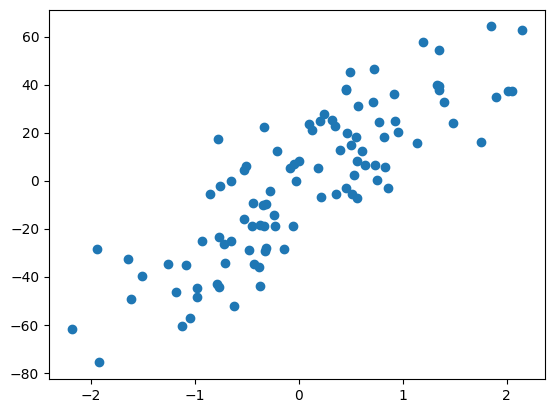

In [2]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

plt.scatter(X,y)

from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train,y_train)
print(reg.coef_)
print(reg.intercept_)

#### Observe the Effect of Alpha

We first create a simple regression dataset and fit a Linear Regression model as a baseline. Then we train Lasso models with different `alpha` values.

As `alpha` increases, the coefficient is penalized more strongly. The fitted line can become flatter because the coefficient is pushed toward zero.

**What to observe :** Compare the fitted lines. A very large `alpha` may underfit the data because the model becomes too simple.

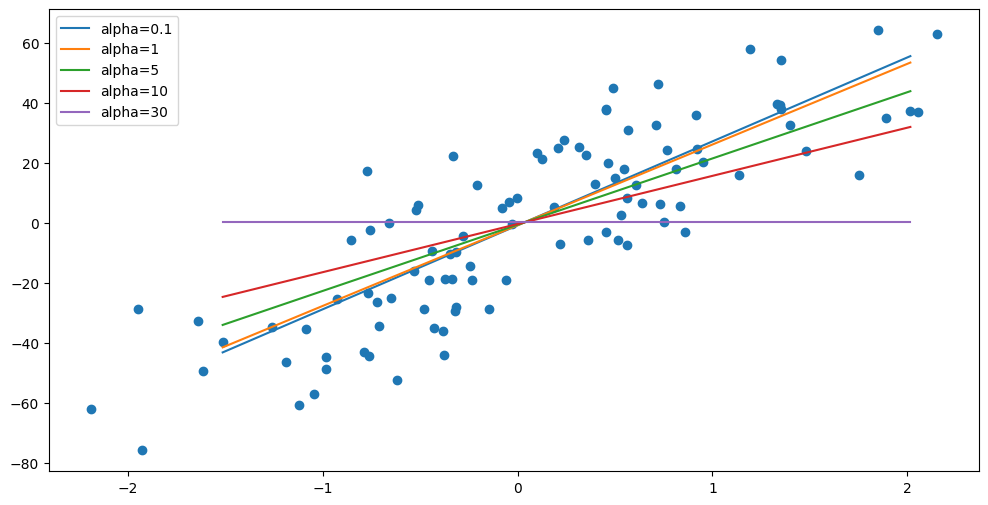

In [3]:
alphas = [0.1, 1, 5, 10, 30]
plt.figure(figsize=(12,6))
plt.scatter(X,y)
for i in alphas:
    L = Lasso(alpha=i, max_iter=10000)
    L.fit(X_train,y_train)
    order = np.argsort(X_test[:, 0])
    plt.plot(X_test[order], L.predict(X_test[order]), label='alpha={}'.format(i))
plt.legend()
plt.show()
    

#### Lasso with Polynomial Features

A polynomial model can represent curved relationships by creating additional features such as $x^2$, $x^3$, and higher powers. A high polynomial degree can create many coefficients and make the model overly flexible.

Lasso can control this complexity by shrinking coefficients. Some polynomial coefficients may become exactly zero, effectively removing their corresponding terms from the fitted model.

The curves below compare different regularization strengths. A larger `alpha` generally produces a simpler fit.

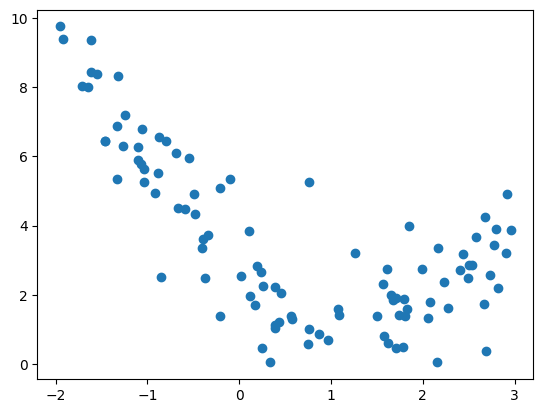

In [4]:
m = 100
x1 = 5 * np.random.rand(m, 1) - 2
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 + np.random.randn(m, 1)

plt.scatter(x1, x2)
plt.show()

C:\Users\us\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.352e+01, tolerance: 5.739e-02
  model = cd_fast.enet_coordinate_descent(
C:\Users\us\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.969e+01, tolerance: 5.739e-02
  model = cd_fast.enet_coordinate_descent(
C:\Users\us\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the

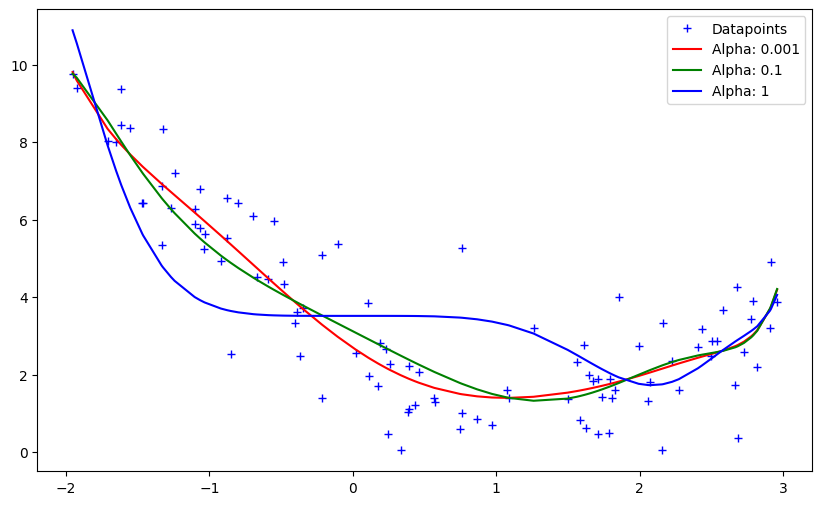

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

def get_preds_lasso(x1, x2, alpha):
    model = Pipeline([
        ('poly_feats', PolynomialFeatures(degree=16)),
        ('lasso', Lasso(alpha=alpha, max_iter=10000))
    ])
    model.fit(x1, x2)
    return model.predict(x1)

alphas = [0.001, 0.1, 1]
cs = ['r', 'g', 'b']

plt.figure(figsize=(10, 6))
plt.plot(x1, x2, 'b+', label='Datapoints')

for alpha, c in zip(alphas, cs):
    preds = get_preds_lasso(x1, x2, alpha)
    # Plot
    plt.plot(sorted(x1[:, 0]), preds[np.argsort(x1[:, 0])], c, label='Alpha: {}'.format(alpha))

plt.legend()
plt.show()

#### Ridge vs Lasso: Practical Example

Ridge and Lasso both add regularization to Linear Regression, but their penalties behave differently:

- **Ridge (L2):** penalizes the squared coefficients. It usually shrinks coefficients toward zero, but rarely makes them exactly zero.
- **Lasso (L1):** penalizes the absolute coefficients. It can make some coefficients exactly zero, so it can remove less useful features.

In the example below, we create a dataset with 10 features, but only a few features are used to generate the target. We standardize the input features because regularization is sensitive to feature scale, then compare the learned coefficients.

A coefficient close to zero indicates that the model is assigning little weight to that feature. Lasso may set some coefficients exactly to zero, while Ridge generally retains all features.

In [6]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

# Create data where only 3 of the 10 features are informative
X_compare, y_compare = make_regression(
    n_samples=300,
    n_features=10,
    n_informative=3,
    noise=15,
    random_state=42
)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_compare, y_compare, test_size=0.2, random_state=42
)

# Scale features using training data only
scaler = StandardScaler()
X_train_c = scaler.fit_transform(X_train_c)
X_test_c = scaler.transform(X_test_c)

# Fit Ridge and Lasso
ridge_model = Ridge(alpha=10)
lasso_model = Lasso(alpha=10, max_iter=10000)

ridge_model.fit(X_train_c, y_train_c)
lasso_model.fit(X_train_c, y_train_c)

# Compare coefficients and test performance
comparison = pd.DataFrame({
    "Feature": [f"Feature_{i+1}" for i in range(X_train_c.shape[1])],
    "Ridge Coefficient": ridge_model.coef_,
    "Lasso Coefficient": lasso_model.coef_
})

ridge_pred = ridge_model.predict(X_test_c)
lasso_pred = lasso_model.predict(X_test_c)

print("Ridge R2:", round(r2_score(y_test_c, ridge_pred), 3))
print("Ridge RMSE:", round(np.sqrt(mean_squared_error(y_test_c, ridge_pred)), 3))
print("Lasso R2:", round(r2_score(y_test_c, lasso_pred), 3))
print("Lasso RMSE:", round(np.sqrt(mean_squared_error(y_test_c, lasso_pred)), 3))

comparison


Ridge R2: 0.989
Ridge RMSE: 14.331
Lasso R2: 0.98
Lasso RMSE: 19.592


,Feature,Ridge Coefficient,Lasso Coefficient
0,Feature_1,-0.925828,-0.000000
1,Feature_2,1.153537,0.000000
2,Feature_3,0.167189,0.000000
3,Feature_4,0.185540,0.000000
4,Feature_5,23.981751,15.643200
5,Feature_6,100.977098,95.063108
6,Feature_7,0.863233,-0.000000
7,Feature_8,-0.847196,-0.000000
8,Feature_9,-0.017677,0.000000
9,Feature_10,72.397666,66.623500


**How to interpret the comparison**

- Look at the `Ridge Coefficient` and `Lasso Coefficient` columns.
- Ridge generally keeps a coefficient for every feature, although it shrinks their magnitudes.
- Lasso may assign an exact zero to some features. Those features are not used by the final linear prediction.
- Compare R² and RMSE on the same test set. A higher R² and lower RMSE indicate better predictive performance for this split.

The exact coefficients and metrics depend on the dataset and chosen `alpha`. In practice, choose `alpha` with cross-validation rather than assuming one value is always best.

#### Ridge vs Lasso: Quick Comparison

| Aspect | Ridge Regression | Lasso Regression |
|:--|:--|:--|
| Penalty | L2: sum of squared coefficients | L1: sum of absolute coefficients |
| Coefficient effect | Shrinks coefficients toward zero | Can shrink coefficients exactly to zero |
| Feature selection | Does not usually remove features | Can perform feature selection |
| Correlated features | Often distributes weights across correlated features | May select one feature and suppress others |
| Useful when | Many features contribute, including correlated features | Only a smaller subset of features may be important |

#### Key Takeaways

- Both methods reduce overfitting by penalizing large coefficients.
- Ridge is useful when many features contribute to the target, especially when features are correlated.
- Lasso is useful when you want a simpler model and automatic feature selection.
- Standardize features before applying Ridge or Lasso when their scales differ.
- Select `alpha` using cross-validation and keep the test set for final evaluation.